# HI5312 — Module 6: Group Project Studio

**Purpose:** This module is a project workspace. It does not introduce new technical content. It helps your group organize, document, complete, and present your health informatics group project.

**Course framework:** Better Questions → Better Data → Better Analysis → Better Decisions → Better Health

**Tools used:** GitHub, GitHub Codespaces, PostgreSQL, SQL, Python 3.12.12, pandas, Tableau, and PowerPoint.

## Clinical Request

Your team has been asked by a healthcare leadership group to answer an important clinical or operational question using the approved course dataset. Your final product should be reproducible, clearly documented, and understandable to a healthcare audience.

Your job is to turn a broad healthcare problem into a clear question, acquire and prepare the data, analyze it responsibly, visualize the findings, and present a recommendation.

## Student Learning Goals

By completing the Group Project, your team will demonstrate that you can:

- define a healthcare analytics question;
- identify relevant data sources and variables;
- write SQL to retrieve and summarize data;
- use Python to clean, validate, and explore data;
- create a Tableau dashboard that communicates findings;
- document assumptions and limitations;
- collaborate as a project team; and
- present findings to a professional audience.

## Group Project Workflow

Use this notebook as the central project workspace.

1. Define the question.
2. Identify tables, variables, and cohort criteria.
3. Write SQL extraction and validation queries.
4. Load the results into Python.
5. Clean and document the dataset.
6. Explore patterns and create summary tables.
7. Export Tableau-ready files.
8. Build the dashboard.
9. Prepare the final presentation.
10. Submit the final project package.

## Team Information

**Team name:**  

**Team members:**  

**Project title:**  

**Primary stakeholder:**  

**Dataset:**  

**Primary clinical or operational question:**

## Project Charter

Complete this section before starting the technical work.

| Section | Team Response |
|---|---|
| Background |  |
| Problem statement |  |
| Primary question |  |
| Intended audience |  |
| Unit of analysis |  |
| Key variables |  |
| Expected deliverables |  |
| Major risks or limitations |  |
| Team roles |  |

## Milestone Tracker

Use this checklist to monitor progress.

- [ ] Project question approved
- [ ] Relevant tables identified
- [ ] SQL extraction query drafted
- [ ] SQL validation queries completed
- [ ] Python notebook started
- [ ] Data cleaning decisions documented
- [ ] Exploratory summaries completed
- [ ] Tableau-ready CSV exported
- [ ] Tableau dashboard draft completed
- [ ] Presentation draft completed
- [ ] README updated
- [ ] Final files submitted

## Database and Codespaces setup

This notebook works in **two modes**:

- **PostgreSQL mode** (preferred for SQL instruction): connects to the course database and runs actual SQL queries against `mimiciv_hosp`.
- **CSV fallback mode**: if PostgreSQL is unavailable, loads the MIMIC-IV Demo `patients` and `admissions` CSV files and runs equivalent pandas examples. **CSV fallback is not SQL execution**; SQL-specific exercises are skipped with an explanation.

Run the notebook **from the top**. The default Codespaces workspace is `/workspaces/hi5304-notebooks`. CSV data can be `.csv` or `.csv.gz` in `data/mimic-iv-demo/hosp`. The PostgreSQL settings use environment variables when supplied; classroom defaults are for course environments only.

In [1]:
# Verify the Python environment
import sys
print(sys.version)

3.12.15 (main, Oct  6 2026, 04:39:41) [GCC 12.2.0]


In [2]:
# Imports and shared notebook setup
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from sqlalchemy.exc import SQLAlchemyError

pd.set_option("display.max_columns", 50)

# Resolve the repository from Codespaces or from the notebook's current folder.
workspace = Path("/workspaces/hi5304-notebooks")
if not workspace.is_dir():
    workspace = Path.cwd()
    for parent in (workspace, *workspace.parents):
        if (parent / "learning").is_dir() and (parent / "data").is_dir():
            workspace = parent
            break
print("Workspace:", workspace)

Workspace: /workspaces/hi5304-notebooks


In [3]:
# Connect to PostgreSQL when available; otherwise load local MIMIC-IV Demo CSV files.
# The SQL examples below only execute when database_mode == "postgresql".
pg_host = os.getenv("PGHOST", "db")
pg_port = int(os.getenv("PGPORT", "5432"))
pg_database = os.getenv("PGDATABASE", "hi5304")
pg_user = os.getenv("PGUSER", "hi5304_user")
pg_password = os.getenv("PGPASSWORD", "hi5304")

engine = None
database_mode = "csv"
try:
    url = URL.create(
        "postgresql+psycopg", username=pg_user, password=pg_password,
        host=pg_host, port=pg_port, database=pg_database,
    )
    engine = create_engine(url, pool_pre_ping=True, connect_args={"connect_timeout": 4})
    with engine.connect() as conn:
        db_info = conn.execute(text("SELECT current_database(), current_user")).one()
        has_tables = conn.execute(text("""
            SELECT to_regclass('mimiciv_hosp.patients') IS NOT NULL
               AND to_regclass('mimiciv_hosp.admissions') IS NOT NULL
        """)).scalar()
    if not has_tables:
        raise RuntimeError("MIMIC-IV hospital tables are not loaded in PostgreSQL")
    database_mode = "postgresql"
    print("Connected to PostgreSQL:", db_info)
except (Exception) as exc:
    if engine is not None:
        engine.dispose()
    engine = None
    print("PostgreSQL unavailable:", type(exc).__name__, str(exc)[:240])
    print("Trying local MIMIC-IV Demo CSV files instead.")

hosp = workspace / "data" / "mimic-iv-demo" / "hosp"
icu = hosp.parent / "icu"

def load_mimic_table(name, folder=None):
    folder = hosp if folder is None else Path(folder)
    for suffix in (".csv", ".csv.gz"):
        path = folder / (name + suffix)
        if path.is_file():
            df = pd.read_csv(path, low_memory=False)
            print(f"Loaded {name}: {len(df):,} rows from {path}")
            return df
    raise FileNotFoundError(
        f"Could not find {name}.csv or {name}.csv.gz in {folder}. "
        "Upload the MIMIC-IV Demo files under data/mimic-iv-demo/hosp and icu."
    )

patients_csv = admissions_csv = None
if database_mode == "csv":
    patients_csv = load_mimic_table("patients")
    admissions_csv = load_mimic_table("admissions")
print("Active mode:", database_mode)

PostgreSQL unavailable: RuntimeError MIMIC-IV hospital tables are not loaded in PostgreSQL
Trying local MIMIC-IV Demo CSV files instead.
Loaded patients: 100 rows from /workspaces/hi5304-notebooks/data/mimic-iv-demo/hosp/patients.csv
Loaded admissions: 275 rows from /workspaces/hi5304-notebooks/data/mimic-iv-demo/hosp/admissions.csv
Active mode: csv


In [4]:
# Execute actual SQL only when the PostgreSQL database is connected.
def read_query(sql: str, params=None) -> pd.DataFrame:
    if database_mode != "postgresql":
        raise RuntimeError(
            "SQL requires PostgreSQL with MIMIC-IV tables. "
            "This session is in CSV fallback mode; use the pandas examples below."
        )
    with engine.connect() as conn:
        return pd.read_sql_query(text(sql), conn, params=params)

def show_sql_or_note(sql: str):
    if database_mode == "postgresql":
        return read_query(sql)
    print("SQL query skipped: PostgreSQL is unavailable. See CSV/pandas exercises below.")
    return None

## Step 1 — Inspect Available Schemas and Tables

Use this section to identify the tables your project might need.

In [18]:
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

url = URL.create(
    "postgresql+psycopg",
    username=os.getenv("PGUSER", "hi5304_user"),
    password=os.getenv("PGPASSWORD", "hi5304"),
    host=os.getenv("PGHOST", "db"),
    port=int(os.getenv("PGPORT", "5432")),
    database=os.getenv("PGDATABASE", "hi5304"),
)

try:
    engine = create_engine(url, pool_pre_ping=True)

    with engine.connect() as conn:
        result = conn.execute(
            text("SELECT current_database(), current_user")
        ).fetchone()

    print("PostgreSQL connection successful:", result)

except Exception as e:
    print("PostgreSQL connection failed:")
    print(type(e).__name__, str(e))

PostgreSQL connection successful: ('hi5304', 'hi5304_user')


In [19]:
schema_query = """
SELECT schema_name FROM information_schema.schemata
WHERE schema_name LIKE 'mimiciv%' ORDER BY schema_name;
"""
show_sql_or_note(schema_query)

SQL query skipped: PostgreSQL is unavailable. See CSV/pandas exercises below.


In [6]:
tables_query = """
SELECT table_schema, table_name FROM information_schema.tables
WHERE table_schema LIKE 'mimiciv%' ORDER BY table_schema, table_name;
"""
show_sql_or_note(tables_query)

SQL query skipped: PostgreSQL is unavailable. See CSV/pandas exercises below.


## Step 2 — Select Project Tables

List the tables your team plans to use.

| Table | Why it is needed | Key fields |
|---|---|---|
|  |  |  |
|  |  |  |
|  |  |  |

In [7]:
# Inspect table columns (SQL mode) or DataFrame columns (CSV mode)
selected_schema = "mimiciv_hosp"
selected_table = "patients"
if database_mode == "postgresql":
    columns_query = """
    SELECT column_name, data_type FROM information_schema.columns
    WHERE table_schema = :schema AND table_name = :table
    ORDER BY ordinal_position;
    """
    display(read_query(columns_query, {"schema": selected_schema, "table": selected_table}))
else:
    display(pd.DataFrame({"column_name": patients_csv.columns,
                          "data_type": patients_csv.dtypes.astype(str).values}))

,column_name,data_type
0,subject_id,int64
1,gender,str
2,anchor_age,int64
3,anchor_year,int64
4,anchor_year_group,str
5,dod,str


## Step 3 — SQL Workspace

Write your extraction query below. Keep validation queries separate from your final extraction query.

In [8]:
# Example project extraction. Edit project_sql for your group's research question.
project_sql = """
SELECT p.subject_id, p.gender, p.anchor_age,
       a.hadm_id, a.admittime, a.dischtime, a.admission_type
FROM mimiciv_hosp.patients AS p
JOIN mimiciv_hosp.admissions AS a ON p.subject_id = a.subject_id
LIMIT 20;
"""
if database_mode == "postgresql":
    project_df = read_query(project_sql)
else:
    # Pandas equivalent for the course CSV demonstration (not SQL execution).
    project_df = patients_csv[["subject_id", "gender", "anchor_age"]].merge(
        admissions_csv[["subject_id", "hadm_id", "admittime", "dischtime", "admission_type"]],
        on="subject_id", how="inner", validate="one_to_many"
    ).head(20).copy()
print("Rows extracted:", len(project_df))
display(project_df.head())

Rows extracted: 20


,subject_id,gender,anchor_age,hadm_id,admittime,dischtime,admission_type
0,10014729,F,21,23300884,2125-03-19 16:58:00,2125-03-28 13:37:00,EW EMER.
1,10014729,F,21,28889419,2125-02-27 07:15:00,2125-03-06 14:25:00,SURGICAL SAME DAY ADMISSION
2,10003400,F,72,23559586,2137-08-04 00:07:00,2137-09-02 17:05:00,URGENT
3,10003400,F,72,20214994,2137-02-24 10:00:00,2137-03-19 15:45:00,URGENT
4,10003400,F,72,27296885,2136-12-31 21:40:00,2137-01-03 17:05:00,EW EMER.


## Step 4 — SQL Validation Queries

Use validation queries to confirm counts, row uniqueness, missingness, and expected table relationships.

In [9]:
validation_count_query = "SELECT COUNT(*) AS row_count FROM mimiciv_hosp.admissions;"
if database_mode == "postgresql":
    display(read_query(validation_count_query))
else:
    display(pd.DataFrame({"row_count": [len(admissions_csv)]}))
    print("Count computed with pandas, not SQL.")

,row_count
0,275


Count computed with pandas, not SQL.


In [10]:
duplicate_review_query = """
SELECT hadm_id, COUNT(*) AS row_count
FROM mimiciv_hosp.admissions
GROUP BY hadm_id HAVING COUNT(*) > 1 ORDER BY row_count DESC;
"""
if database_mode == "postgresql":
    display(read_query(duplicate_review_query))
else:
    counts = admissions_csv.groupby("hadm_id", dropna=False).size()
    display(counts[counts > 1].rename("row_count").reset_index())
    print("Duplicate check computed with pandas, not SQL.")

,hadm_id,row_count


Duplicate check computed with pandas, not SQL.


## Step 5 — Load the Project Dataset into Python

Once the SQL extraction query is ready, load the result into a pandas DataFrame.

In [11]:
# The project dataset was loaded in Step 3.
# After changing project_sql, rerun the Step 3 extraction cell first.
print("Mode:", database_mode)
print("Rows:", project_df.shape[0])
print("Columns:", project_df.shape[1])
display(project_df.head())

Mode: csv
Rows: 20
Columns: 7


,subject_id,gender,anchor_age,hadm_id,admittime,dischtime,admission_type
0,10014729,F,21,23300884,2125-03-19 16:58:00,2125-03-28 13:37:00,EW EMER.
1,10014729,F,21,28889419,2125-02-27 07:15:00,2125-03-06 14:25:00,SURGICAL SAME DAY ADMISSION
2,10003400,F,72,23559586,2137-08-04 00:07:00,2137-09-02 17:05:00,URGENT
3,10003400,F,72,20214994,2137-02-24 10:00:00,2137-03-19 15:45:00,URGENT
4,10003400,F,72,27296885,2136-12-31 21:40:00,2137-01-03 17:05:00,EW EMER.


In [ ]:
project_df.info()

## Step 6 — Data Cleaning Log

Document every data cleaning decision. Do not clean silently.

| Date | Variable | Issue | Decision | Rationale | Team member |
|---|---|---|---|---|---|
|  |  |  |  |  |  |

In [12]:
# Basic data quality review; safe for empty project datasets.
missing_summary = project_df.isna().sum().rename("missing_count").to_frame()
missing_summary["missing_percent"] = (
    (100 * missing_summary["missing_count"] / len(project_df)).round(1)
    if len(project_df) else 0.0
)
display(missing_summary.sort_values("missing_count", ascending=False))

,missing_count,missing_percent
subject_id,0,0.0
gender,0,0.0
anchor_age,0,0.0
hadm_id,0,0.0
admittime,0,0.0
dischtime,0,0.0
admission_type,0,0.0


## Step 7 — Exploratory Analysis Workspace

Use this section for descriptive summaries, grouped summaries, and initial visualizations.

In [13]:
# Summary statistics for numeric columns
project_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subject_id,20.0,NaN,NaN,NaN,10009529.7,11211.077295,10002428.0,10002428.0,10003400.0,10014729.0,10032725.0
gender,20,1,F,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anchor_age,20.0,NaN,NaN,NaN,63.9,20.263787,21.0,48.0,72.0,80.0,80.0
hadm_id,20.0,NaN,NaN,NaN,25595536.1,3071744.11139,20214994.0,23430364.0,26278997.5,28386999.0,29483621.0
admittime,20,20,2125-03-19 16:58:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dischtime,20,20,2125-03-28 13:37:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type,20,5,EW EMER.,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Example grouped summary. Replace admission_type with a project-relevant variable.
if "admission_type" in project_df.columns:
    display(
        project_df.groupby("admission_type", dropna=False)
        .size()
        .rename("row_count")
        .reset_index()
        .sort_values("row_count", ascending=False)
    )

,admission_type,row_count
1,EW EMER.,11
4,URGENT,4
0,EU OBSERVATION,3
2,OBSERVATION ADMIT,1
3,SURGICAL SAME DAY ADMISSION,1


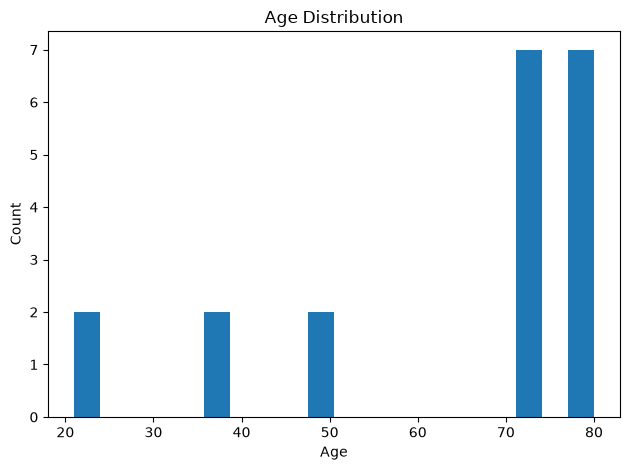

In [15]:
# Optional Python visualization workspace
import matplotlib.pyplot as plt

if "anchor_age" in project_df.columns:
    project_df["anchor_age"].dropna().plot(kind="hist", bins=20)
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## Step 8 — Tableau Export

Export a cleaned or summarized dataset for Tableau. Do not export restricted or unnecessary row-level data.

In [16]:
# Export a course project CSV to a stable location in this repository.
# Review columns and privacy requirements before distributing an export.
output_dir = workspace / "learning" / "hi5312" / "notebooks" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
export_path = output_dir / "group_project_tableau_export.csv"
project_df.to_csv(export_path, index=False)
print("Exported:", export_path)
print("Rows:", len(project_df))

Exported: /workspaces/hi5304-notebooks/learning/hi5312/notebooks/outputs/group_project_tableau_export.csv
Rows: 20


## Step 9 — Tableau Dashboard Notes

Document the dashboard design.

**Audience:**  

**Dashboard purpose:**  

**KPI cards:**  

**Filters:**  

**Worksheets:**  

**Primary recommendation supported by dashboard:**

## Step 10 — Findings and Recommendations

### Key Findings

1.  
2.  
3.  

### Interpretation


### Recommendation


### Limitations

1.  
2.  
3.

## Clinical Decision Point

If you were presenting to the Chief Medical Information Officer tomorrow, what single recommendation would your team make based on your analysis?

Your answer should include:

- the evidence supporting the recommendation;
- the uncertainty or limitation that matters most;
- the next data or workflow question you would investigate; and
- the stakeholder who should act on the recommendation.

## Final Presentation Checklist

- [ ] Clinical question is clear
- [ ] Dataset and cohort are described
- [ ] Methods are understandable
- [ ] SQL and Python workflow is reproducible
- [ ] Dashboard answers the question
- [ ] Findings are specific
- [ ] Recommendation is actionable
- [ ] Limitations are transparent
- [ ] All team members participate
- [ ] Presentation stays within assigned time

## Repository Checklist

Your final repository or submitted folder should include:

- [ ] README.md
- [ ] Project notebook
- [ ] SQL script or documented SQL queries
- [ ] Data dictionary
- [ ] Data cleaning log
- [ ] Tableau workbook or dashboard file
- [ ] Dashboard PDF or screenshots
- [ ] Presentation slides
- [ ] Any required reflection documents

## Individual Reflection

Each student should answer:

1. What was your role on the team?
2. What was the most valuable thing you learned?
3. What was the most challenging part of the project?
4. Which tool added the most value: SQL, Python, or Tableau?
5. What would you do differently next time?
6. How has your understanding of health informatics changed?

## Closing

At the beginning of the course, you learned how to ask meaningful healthcare questions. You then learned how to evaluate data quality, retrieve data with SQL, prepare and explore data with Python, and communicate findings with Tableau.

The Group Project is your opportunity to integrate these skills into a professional health informatics analysis.

The tools are important, but your greatest contribution is your ability to transform data into decisions that improve healthcare.

In [17]:
# Close database connections when finished.
if engine is not None:
    engine.dispose()
    print("PostgreSQL connection closed.")
else:
    print("No PostgreSQL connection was opened (CSV fallback mode).")

No PostgreSQL connection was opened (CSV fallback mode).
